# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name: Krishna lund**
- **Student ID: 023-24-0271**
- **Section: H**
- **GitHub: https://github.com/Krishnalund/machine-learning-practical-work**
- **Kaggle:  https://www.kaggle.com/krishnalund18**
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source: https://www.kaggle.com/datasets/vedatgul/telco-churn-dataset** <paste the Kaggle URL you used>

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv('Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)
df['TotalCharges'] = df['TotalCharges'].fillna(
    df['TotalCharges'].median()
)
df.drop(columns=['customerID'], inplace=True)
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

print(df.head())
print("Missing values:", df.isnull().sum().sum())

   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes          No  

In [2]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)
# One-hot encoding
df = pd.get_dummies(df, drop_first=True, dtype=int)

# Features and target
X = df.drop(columns=['Churn'])
y = df['Churn']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("\nChurn distribution:")
print(y.value_counts(normalize=True).round(3))

Training data: (5634, 30)
Testing data: (1409, 30)

Churn distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [3]:
# YOUR CODE HERE — unscaled linear SVM
svm_raw = SVC(kernel='linear', random_state=42)

start = time.time()
svm_raw.fit(X_train, y_train)
raw_time = time.time() - start

raw_pred = svm_raw.predict(X_test)

raw_accuracy = accuracy_score(y_test, raw_pred)
raw_f1 = f1_score(y_test, raw_pred, zero_division=0)

print("Unscaled SVM Accuracy:", round(raw_accuracy, 4))
print("Unscaled SVM F1-score:", round(raw_f1, 4))
print("Unscaled Training Time:", round(raw_time, 4), "seconds")

Unscaled SVM Accuracy: 0.7906
Unscaled SVM F1-score: 0.5203
Unscaled Training Time: 990.3815 seconds


In [4]:
# YOUR CODE HERE — scaled linear SVM
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

svm_scaled = SVC(kernel='linear', random_state=42)

start = time.time()
svm_scaled.fit(X_train_s, y_train)
scaled_time = time.time() - start

scaled_pred = svm_scaled.predict(X_test_s)

scaled_accuracy = accuracy_score(y_test, scaled_pred)
scaled_f1 = f1_score(y_test, scaled_pred, zero_division=0)

print("Scaled SVM Accuracy:", round(scaled_accuracy, 4))
print("Scaled SVM F1-score:", round(scaled_f1, 4))
print("Scaled Training Time:", round(scaled_time, 4), "seconds")

scaling_results = pd.DataFrame({
    'Model': ['Unscaled SVM', 'Scaled SVM'],
    'Accuracy': [raw_accuracy, scaled_accuracy],
    'F1-score': [raw_f1, scaled_f1],
    'Training Time': [raw_time, scaled_time]
})

display(scaling_results.round(4))

Scaled SVM Accuracy: 0.7892
Scaled SVM F1-score: 0.5714
Scaled Training Time: 2.8534 seconds


,Model,Accuracy,F1-score,Training Time
0,Unscaled SVM,0.7906,0.5203,990.3815
1,Scaled SVM,0.7892,0.5714,2.8534


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:The unscaled SVM achieved 79.06% accuracy and an F1-score of 0.5203, while the scaled SVM achieved 78.92% accuracy and an F1-score of 0.5714. Scaling slightly decreased accuracy but improved the F1-score. Training time decreased significantly from 990.38 seconds to 2.85 seconds. The unscaled model also took much longer to train.No convergence warning was displayed in the recorded output.*

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:SVM calculates its decision boundary using margins and distances between data points. Features with larger numerical ranges can dominate these calculations, giving smaller-scale features less influence. Scaling puts features on comparable scales, helping the SVM find a more suitable decision boundary and train much faster.*
(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:I will use the scaled features for all subsequent SVM experiments because scaling greatly reduces training time and improves the F1-score in my results. It also prevents features with larger numerical ranges from dominating the decision boundary. The scaler will be fitted only on the training data to prevent data leakage.*

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [11]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
kernels = ['linear', 'rbf', 'poly']
kernel_models = {}
results = []

for kernel in kernels:
    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train_s, y_train)

    pred = model.predict(X_test_s)
    kernel_models[kernel] = model

    results.append({
        'Kernel': kernel,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1-score': f1_score(y_test, pred, zero_division=0),
        'Support Vectors': model.support_.shape[0]
    })

kernel_results = pd.DataFrame(results)


In [9]:
# YOUR CODE HERE — comparison table
display(kernel_results.round(4))



,Kernel,Accuracy,Precision,Recall,F1-score,Support Vectors
0,linear,0.7892,0.6207,0.5294,0.5714,2569
1,rbf,0.7928,0.6444,0.4893,0.5562,2661
2,poly,0.7892,0.6421,0.4652,0.5395,2739


Best kernel: linear


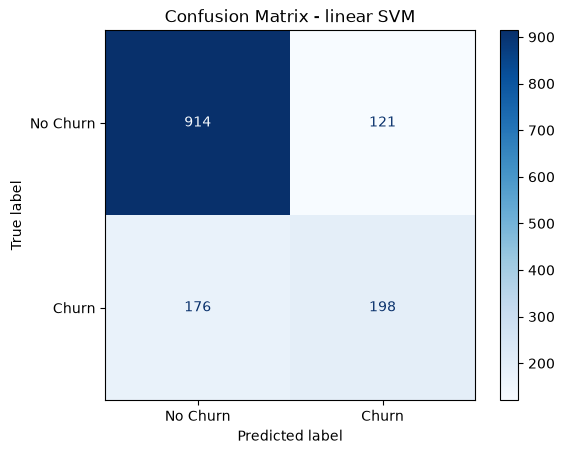

In [10]:
# YOUR CODE HERE — confusion matrix for the best kernel
best_kernel = kernel_results.loc[
    kernel_results['F1-score'].idxmax(), 'Kernel'
]

best_kernel_model = kernel_models[best_kernel]
best_kernel_pred = best_kernel_model.predict(X_test_s)

print("Best kernel:", best_kernel)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_kernel_pred,
    display_labels=['No Churn', 'Churn'],
    cmap='Blues'
)

plt.title(f'Confusion Matrix - {best_kernel} SVM')
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:The linear kernel produced the best F1-score (0.5714), followed by RBF (0.5562) and polynomial (0.5395). Linear performed better because it had higher recall, meaning it detected more churn customers. RBF had the highest accuracy (0.7928), but because the dataset is imbalanced, F1-score is a better metric for comparing performance.*

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:The poly kernel used the most support vectors (2739). This means more training points were needed to define its decision boundary, suggesting greater complexity and overlapping classes. However, it achieved the lowest F1-score, so its extra complexity did not improve performance.*

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:I would choose the linear kernel based on its test F1-score of 0.5714 and recall of 0.5294. However, Part 4 specifically requires tuning an RBF SVM, so I will use RBF for the grid search. This will help me determine whether tuning its C and gamma parameters can improve its performance.*


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [12]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_s)

explained_variance = pca.explained_variance_ratio_

print("Explained variance ratio of PC1:", round(explained_variance[0], 4))
print("Explained variance ratio of PC2:", round(explained_variance[1], 4))
print("Total explained variance ratio:", round(explained_variance.sum(), 4))


Explained variance ratio of PC1: 0.3325
Explained variance ratio of PC2: 0.1198
Total explained variance ratio: 0.4523


In [13]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
from sklearn.svm import SVC

C_values = [0.01, 1, 100]
rbf_models = {}

for c in C_values:
    model = SVC(kernel='rbf', C=c, random_state=42)
    model.fit(X_train_pca, y_train)

    rbf_models[c] = model

    print(f"C = {c}")
    print("Number of support vectors:", model.support_.shape[0])
    print("Support vectors per class:", model.n_support_)
    print("-" * 30)


C = 0.01
Number of support vectors: 2997
Support vectors per class: [1502 1495]
------------------------------
C = 1
Number of support vectors: 2659
Support vectors per class: [1336 1323]
------------------------------
C = 100
Number of support vectors: 2631
Support vectors per class: [1339 1292]
------------------------------


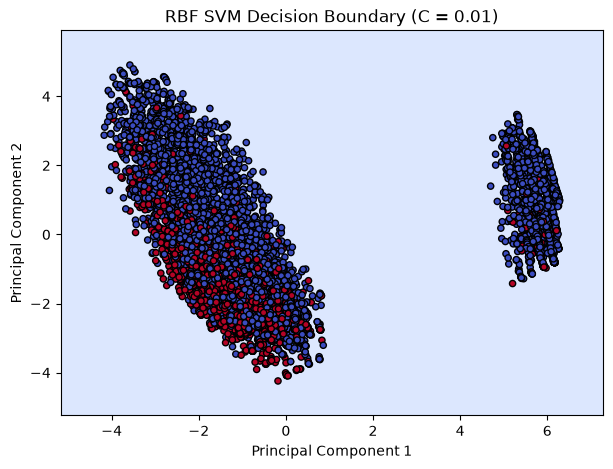

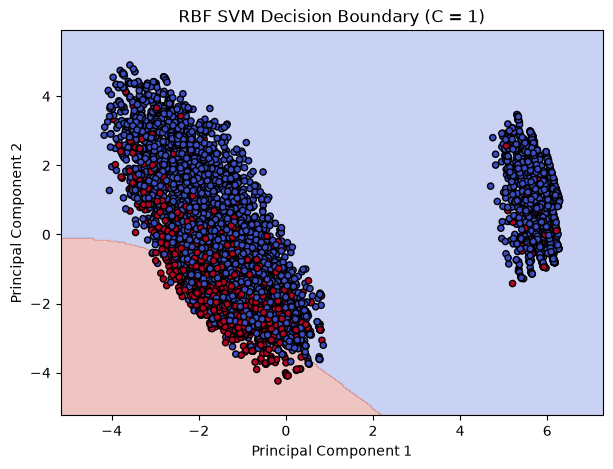

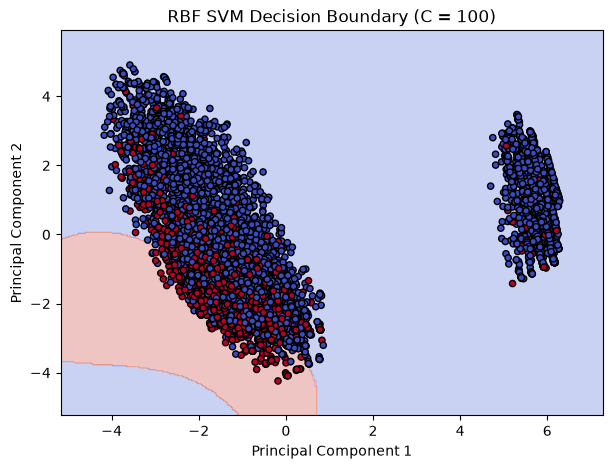

In [14]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
import numpy as np
import matplotlib.pyplot as plt

# Create mesh grid
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Plot decision boundary for each C
for c, model in rbf_models.items():
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid_points)
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(7, 5))

    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

    plt.scatter(
        X_train_pca[:, 0],
        X_train_pca[:, 1],
        c=y_train,
        cmap='coolwarm',
        edgecolors='k',
        s=20
    )

    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title(f'RBF SVM Decision Boundary (C = {c})')
    plt.show()


**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:At C = 0.01, the model predicts almost everything as No Churn. At C = 1, a smooth boundary appears around churn points. At C = 100, the boundary becomes more complex and curved. This happens because higher C penalizes classification errors more strongly, making the model fit the training data more closely.*

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:The number of support vectors decreases as C increases: 2997 (C = 0.01), 2659 (C = 1), and 2631 (C = 100). A small C allows more margin violations, while a large C penalizes errors more strongly. Many support vectors remain because the classes overlap significantly.*

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:C = 0.01 — Underfitting: The model predicts almost everything as No Churn and fails to capture the churn pattern.
C = 100 — Overfitting: The boundary is more complex and may fit individual points or noise.
C = 1 — Best balance: The boundary is smooth and captures the main pattern without too much complexity.*

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:The 2-D plot is only an approximation because PC1 and PC2 explain just 45.2% of the total variance. More than half of the information is missing. Churn and non-churn points may overlap differently in the full feature space, and the plotted boundary may not match the original SVM boundary. Therefore, the plot helps visualize the effect of C but does not show the complete model behavior.*


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [15]:
# YOUR CODE HERE — define param_grid and run GridSearchCV

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1]
}
gs = GridSearchCV(
    estimator=SVC(kernel='rbf', random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
gs.fit(X_train_s, y_train)
print("Best Parameters:", gs.best_params_)
print("Best CV F1-score:", round(gs.best_score_, 4))


Best Parameters: {'C': 100, 'gamma': 0.01}
Best CV F1-score: 0.5877


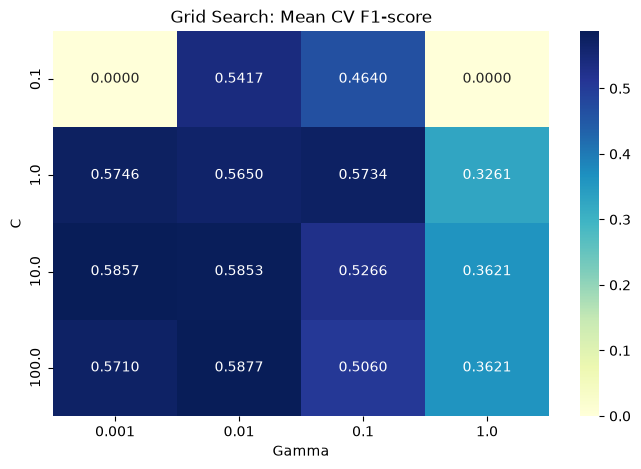

In [16]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
results = pd.DataFrame(gs.cv_results_)

heatmap_data = results.pivot(
    index='param_C',
    columns='param_gamma',
    values='mean_test_score'
)

plt.figure(figsize=(8, 5))
sns.heatmap(heatmap_data, annot=True, fmt='.4f', cmap='YlGnBu')

plt.title('Grid Search: Mean CV F1-score')
plt.xlabel('Gamma')
plt.ylabel('C')
plt.show()


In [17]:
# YOUR CODE HERE — refit best estimator, evaluate on test set

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

best_svm = gs.best_estimator_

y_pred = best_svm.predict(X_test_s)

print("Best Parameters:", gs.best_params_)
print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Test Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Test Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("Test F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Best Parameters: {'C': 100, 'gamma': 0.01}
Test Accuracy: 0.7786
Test Precision: 0.5939
Test Recall: 0.5241
Test F1-score: 0.5568

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.87      0.85      1035
           1       0.59      0.52      0.56       374

    accuracy                           0.78      1409
   macro avg       0.71      0.70      0.70      1409
weighted avg       0.77      0.78      0.77      1409

Confusion Matrix:
[[901 134]
 [178 196]]


**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:The grid search selected C = 100 and gamma = 0.01, with a mean cross-validated F1-score of 0.5877.*

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:There is no clear best region because several combinations have similar F1-scores. The best is C = 100, gamma = 0.01 (F1 = 0.5877), but nearby combinations perform almost as well. Gamma = 1 performs poorly, while some combinations with C = 0.1 give an F1-score of 0, meaning the model fails to identify churners.*

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:The CV F1-score was 0.5877, while the test F1-score was 0.5568, a small gap of 0.031. This is acceptable and suggests the model generalizes reasonably well to unseen data, with no strong sign of overfitting.*

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:Tuning was not worth it in terms of F1-score, which barely improved from 0.5562 to 0.5568. Recall improved, but precision and accuracy decreased. However, tuning helped identify the best parameters. The linear SVM still performed better, with an F1-score of 0.5714.*


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [23]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
from sklearn.svm import SVC
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    PrecisionRecallDisplay
)
import matplotlib.pyplot as plt
svm_none = SVC(
    kernel='rbf',
    C=100,
    gamma=0.01,
    class_weight=None,
    random_state=42
)
svm_none.fit(X_train_s, y_train)
y_pred_none = svm_none.predict(X_test_s)

svm_balanced = SVC(
    kernel='rbf',
    C=100,
    gamma=0.01,
    class_weight='balanced',
    random_state=42
)
svm_balanced.fit(X_train_s, y_train)
y_pred_balanced = svm_balanced.predict(X_test_s)

for name, y_pred in [
    ("Without Class Weight", y_pred_none),
    ("With Balanced Class Weight", y_pred_balanced)
]:
    print(f"\n{name}")
    print("Precision:", round(precision_score(y_test, y_pred), 4))
    print("Recall:", round(recall_score(y_test, y_pred), 4))
    print("F1-score:", round(f1_score(y_test, y_pred), 4))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))




Without Class Weight
Precision: 0.5939
Recall: 0.5241
F1-score: 0.5568
Confusion Matrix:
 [[901 134]
 [178 196]]

With Balanced Class Weight
Precision: 0.5152
Recall: 0.7701
F1-score: 0.6174
Confusion Matrix:
 [[764 271]
 [ 86 288]]


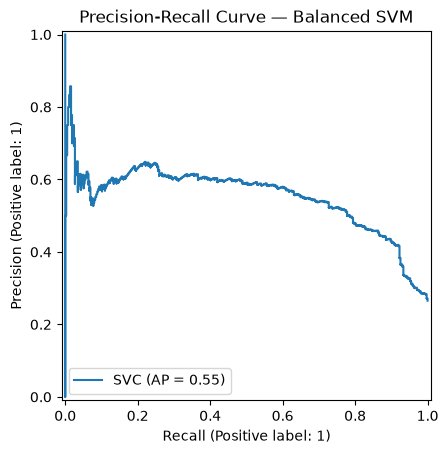

In [24]:
# YOUR CODE HERE — ROC or Precision-Recall curve
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

PrecisionRecallDisplay.from_estimator(
    svm_balanced, X_test_s, y_test
)

plt.title("Precision-Recall Curve — Balanced SVM")
plt.show()

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer: The balanced SVM improved recall from 0.5241 to 0.7701 and F1-score from 0.5568 to 0.6174. However, precision decreased from 0.5939 to 0.5152. The number of false positives also increased from 134 to 271, while false negatives decreased from 178 to 86. Therefore, the balanced model detects more actual churners but also incorrectly flags more loyal customers. It is preferable when identifying potential churners is the main business priority.*

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:A false negative is usually more costly because the business loses a potential customer. Therefore, I would deploy the balanced SVM, which catches 77% of churners compared with 52% for the unweighted model. Although it generates more false alarms, the extra retention offers may cost less than losing customers. The final decision depends on the actual cost of retention offers and the value of saved customers.*

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:Set probability=True in SVC() when you need churn probabilities using predict_proba(). It makes training slower because of internal cross-validation. However, a precision-recall curve can use decision scores without probability estimates, so probability=True is not required for plotting the curve.*


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [25]:
# YOUR CODE HERE — cross-model comparison table
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=10,
        min_samples_split=5, random_state=42
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "SVM (Balanced)": SVC(
        kernel="rbf", C=100, gamma=0.01,
        class_weight="balanced", random_state=42
    )
}
results = []

for name, model in models.items():
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })

comparison_df = pd.DataFrame(results).set_index("Model")

print(comparison_df.round(4))



                     Accuracy  Precision  Recall  F1-score
Model                                                     
Decision Tree          0.7410     0.5125  0.4920    0.5020
Random Forest          0.8055     0.6689  0.5294    0.5910
Logistic Regression    0.8070     0.6584  0.5668    0.6092
KNN                    0.7693     0.5694  0.5374    0.5530
SVM (Balanced)         0.7466     0.5152  0.7701    0.6174


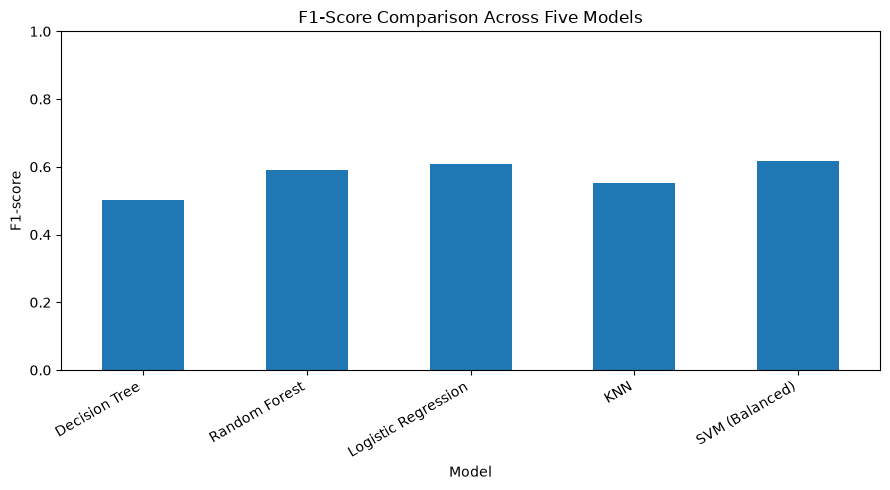

In [21]:
# YOUR CODE HERE — bar chart of F1-score across models
import matplotlib.pyplot as plt

comparison_df["F1-score"].plot(kind="bar", figsize=(9, 5))

plt.title("F1-Score Comparison Across Five Models")
plt.xlabel("Model")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:The Balanced SVM performs best, with an F1-score of 0.6174 and recall of 0.7701. However, its F1-score is only slightly higher than Logistic Regression's (0.6092). Its major advantage is recall: it identifies more actual churners, although it also produces more false positives.*

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:SVM’s extra training cost is only partly worth it. It performs much better than Decision Tree, but its F1-score is only slightly higher than Logistic Regression’s. Logistic Regression is faster, easier to interpret, and has better accuracy and precision. SVM is preferable when catching more churners is the main priority; otherwise, Logistic Regression is a practical choice.*

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:Deploy the Balanced SVM because identifying as many potential churners as possible is the main priority. It achieves the highest recall (0.7701) and F1-score (0.6174), catching about 77% of churners. However, if retention offers are expensive and interpretability matters more, Logistic Regression is a strong alternative with better accuracy (0.8070) and precision (0.6584).*


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [22]:
# YOUR CODE HERE — generate and save svm_predictions.csv
import pandas as pd
y_pred = svm_balanced.predict(X_test_s)

y_score = svm_balanced.decision_function(X_test_s)
predictions_df = pd.DataFrame({
    "True_Label": y_test.values,
    "Predicted_Label": y_pred,
    "Churn_Score": y_score
})
predictions_df.to_csv("svm_predictions.csv", index=False)

print("Predictions saved to svm_predictions.csv")
print(predictions_df.head())

Predictions saved to svm_predictions.csv
   True_Label  Predicted_Label  Churn_Score
0           0                0    -1.779096
1           0                1     1.259430
2           0                0    -2.177052
3           0                0    -0.154549
4           0                0    -2.206137


**Executive Summary**

*The Balanced SVM with an RBF kernel was selected as the final model for churn prediction. It achieved an F1-score of 0.6174 and recall of 0.7701, identifying approximately 77% of actual churners. Using class_weight='balanced' improved recall compared with the unweighted SVM. However, precision decreased to 0.5152, meaning more loyal customers were incorrectly flagged as potential churners. This trade-off was accepted because missing potential churners may be more costly than offering retention incentives to loyal customers. The model's predictions and decision scores were saved in svm_predictions.csv. One limitation is that the model was evaluated on a single train-test split, so its performance may vary on new customer data.*

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:The most surprising result was that balancing the SVM increased recall from 0.5241 to 0.7701 and improved its F1-score from 0.5568 to 0.6174, despite reducing precision.*

(b) If you had one more hour, what would you try next?

*Your answer:I would try a balanced Logistic Regression model and adjust its classification threshold to improve churn detection. Then, I would compare its recall, precision, and F1-score with the Balanced SVM to determine which model provides the best business trade-off.*
